In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
df = pd.read_csv('framingham.csv')
df.head()


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [3]:
df.describe()


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [6]:
#check for duplicate rows
duo_rows = df.duplicated().sum()
print(f"Number of duplicate rows: {duo_rows}")

#missing values
miss_val = df.isnull().sum()
print("Missing values in each column:")
print(miss_val)

#filling the missingval with mean
df = df.fillna(df.mean())
print("Missing values filled with mean.")
print("Missing values after filling:")
print(df.isnull().sum())

Number of duplicate rows: 0
Missing values in each column:
male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64
Missing values filled with mean.
Missing values after filling:
male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64


In [9]:
#prediction target
target = 'TenYearCHD'

#checking idf the target variable is balanced or not
target_counts = df[target].value_counts()
print(f"Counts of target variable '{target}':")
print(target_counts)

#35696 / 644 an imbalanced dataset

#smote wull be used
from imblearn.over_sampling import SMOTE

print("Before SMOTE, counts of label '1': {}".format(sum(df[target]==1)))
print("Before SMOTE, counts of label '0': {} \n".format(sum(df[target]==0)))



Counts of target variable 'TenYearCHD':
TenYearCHD
0    3596
1     644
Name: count, dtype: int64
Before SMOTE, counts of label '1': 644
Before SMOTE, counts of label '0': 3596 



In [11]:
#we will fix label 1
smote  = SMOTE(sampling_strategy=0.5, random_state=42)

#original split
X_train, X_test, Y_train, Y_test  = train_test_split(
    df.drop(columns = [target], axis=1),
    df[target],
    test_size=0.2,
    random_state=42
)
print("Before SMOTE, counts of label '1' in training set: {}".format(sum(Y_train==1)))
print("Before SMOTE, counts of label '0' in training set: {} \n".format(sum(Y_train==0)))   

#now using smote
X_train_smote, Y_train_smote = smote.fit_resample(X_train, Y_train)

print("After SMOTE, counts of label '1' in training set: {}".format(sum(Y_train_smote==1)))
print("After SMOTE, counts of label '0' in training set: {} \n".format(sum(Y_train_smote==0)))




Before SMOTE, counts of label '1' in training set: 521
Before SMOTE, counts of label '0' in training set: 2871 

After SMOTE, counts of label '1' in training set: 1435
After SMOTE, counts of label '0' in training set: 2871 



In [12]:
#target proportions
print(df[target].value_counts(normalize=True, dropna=False))

TenYearCHD
0    0.848113
1    0.151887
Name: proportion, dtype: float64


In [15]:
#identify the feature types
cat_features  = df.select_dtypes(include=['object']).columns.tolist()
num_features  = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f"Categorical features: {cat_features}")
print(f"Numerical features: {num_features}")

#all are numerical features 
print(df['education'].head())


Categorical features: []
Numerical features: ['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']
0    4.0
1    2.0
2    1.0
3    3.0
4    3.0
Name: education, dtype: float64


In [20]:
#scaling the features
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()
X_Train_scaled = standard_scaler.fit_transform(X_train_smote)
X_Test_scaled = standard_scaler.transform(X_test)



In [22]:
#fitting logistic regression model

model = LogisticRegression(max_iter=1000)

model.fit(X_Train_scaled, Y_train_smote)

#predicting on the test set
y_pred = model.predict(X_Test_scaled)

#evaluating the model
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Accuracy:", accuracy_score(Y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(Y_test, y_pred))
print("Classification Report:\n", classification_report(Y_test, y_pred))


Accuracy: 0.7841981132075472
Confusion Matrix:
 [[636  89]
 [ 94  29]]
Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.88      0.87       725
           1       0.25      0.24      0.24       123

    accuracy                           0.78       848
   macro avg       0.56      0.56      0.56       848
weighted avg       0.78      0.78      0.78       848



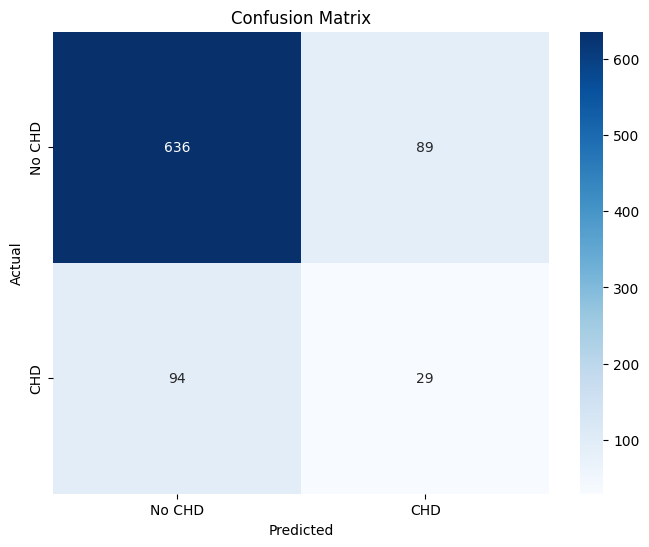

In [23]:
#plotting the confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(Y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['No CHD', 'CHD'], yticklabels=['No CHD', 'CHD'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()